# SAT predicates and unknown-count search

Run this notebook with the project's pinned Python 3.12 dependencies and its src directory, either from a source checkout or an unpacked code bundle.

The oracle evaluates the supplied CNF. The controller does not receive an exact solution count or a hardcoded satisfying assignment. Exhaustive checks below are bounded diagnostics, performed after the seeded searches.

References: Boyer, Brassard, Høyer and Tapp (1998), https://arxiv.org/abs/quant-ph/9605034; Brassard, Høyer, Mosca and Tapp (2002), https://arxiv.org/abs/quant-ph/0005055. We use Qiskit core (Apache-2.0), https://github.com/Qiskit/qiskit.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from qiskit import qasm3
from qiskit.quantum_info import Statevector

root = Path.cwd()
if not (root / "src").exists() and (root.parent / "src").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

from openquantum.grover_sat import (
    CNF, compute_clause_register, build_cnf_phase_oracle,
    build_sat_grover_circuit, amplification_probability, exhaustive_solutions, replay_recorded_attempts, preflight_sat_circuit,
)
from openquantum.bbht_search import BBHTConfig, run_bbht
from openquantum.resource_estimation import prepare_measured_circuit

cnf = CNF(4, [[1, 2], [-1, 3], [-2, -3], [4]])
print(cnf)

CNF(n_variables=4, clauses=((1, 2), (-1, 3), (-2, -3), (4,)))


## An actual reversible predicate

Positive k means variable k-1; negative k means its negation. The assignment occupies the low-index data qubits and clause scratch starts in zero. The oracle computes clauses, marks their conjunction by phase, and uncomputes every clause.

{'assignment_qubits': 4, 'clause_scratch': 4, 'clean_work': 1, 'total_qubits': 9}


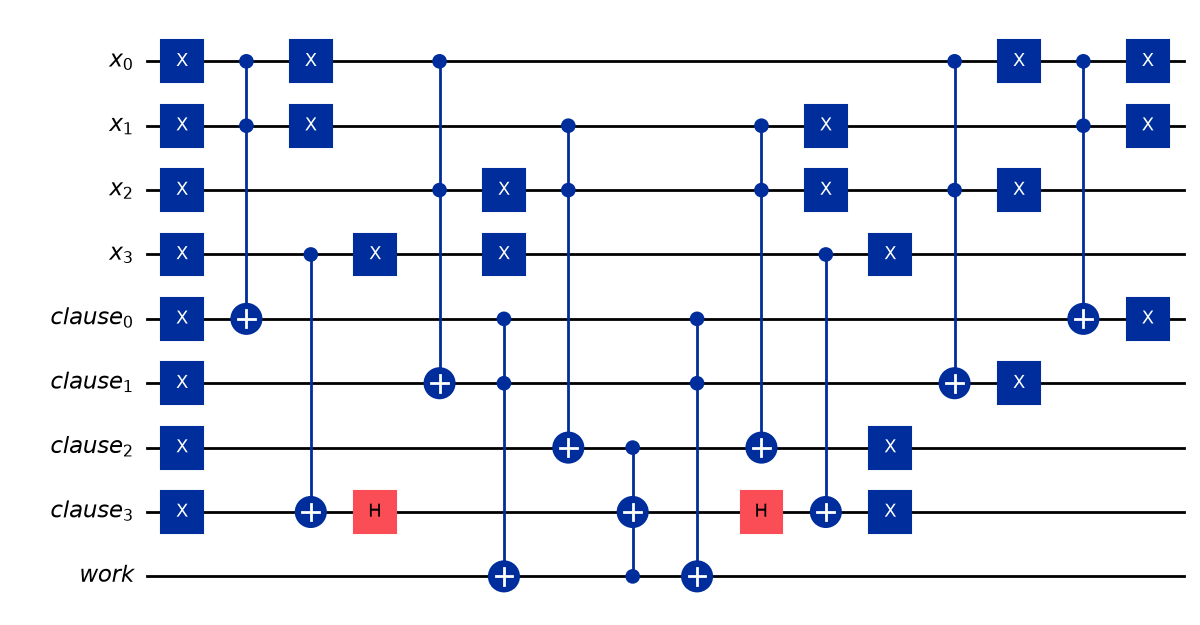

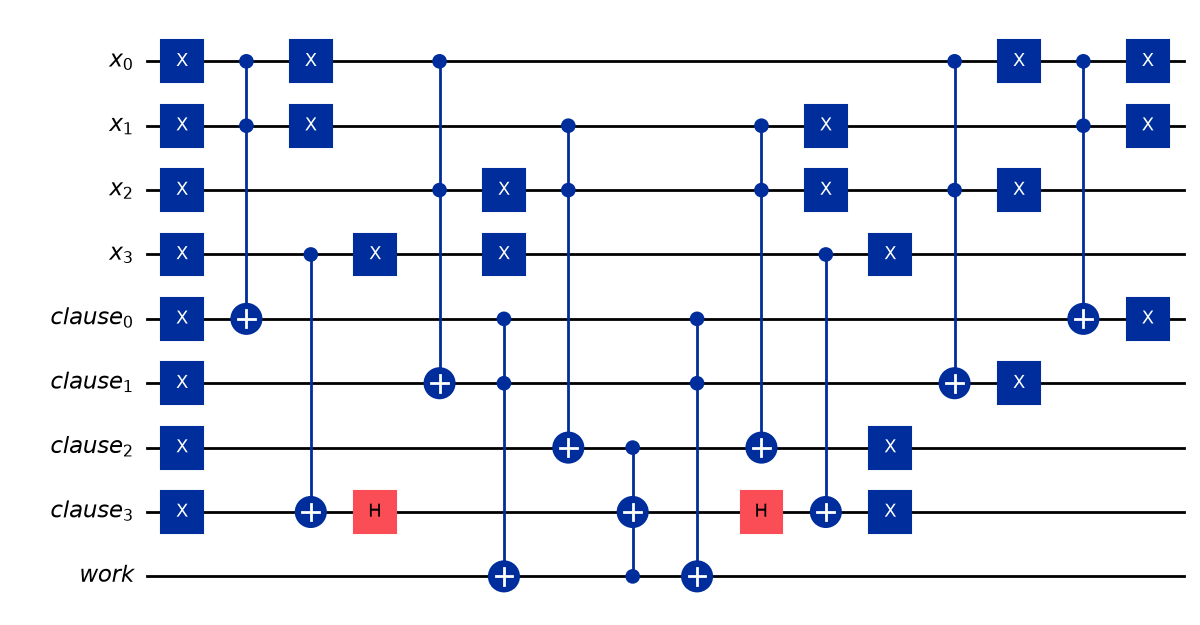

In [2]:
oracle = build_cnf_phase_oracle(cnf)
print({"assignment_qubits": cnf.n_variables, "clause_scratch": len(cnf.clauses), "clean_work": cnf.num_clean_work_qubits, "total_qubits": oracle.num_qubits})
oracle.draw(output="mpl", fold=28)

## Count-agnostic seeded searches

All three predetermined SAT seeds are retained. The same formula is used to verify measured candidates classically. A capped failure is inconclusive. No exhaustive count is passed to the controller.

In [3]:
seeds = (7, 11, 29)
searches = [
    run_bbht(cnf, BBHTConfig(seed=seed, max_attempts=16, max_oracle_calls=32, growth=1.2, max_simulation_qubits=14))
    for seed in seeds
]
summary = []
for seed, result in zip(seeds, searches):
    summary.append({
        "seed": seed,
        "status": result["status"],
        "attempts": [
            {"attempt": i + 1, "iterations": attempt["iterations"],
             "candidate": attempt["candidate_bitstring"], "verified": attempt["verified"]}
            for i, attempt in enumerate(result["attempts"])
        ],
        "oracle_calls_recorded": sum(attempt["iterations"] for attempt in result["attempts"]),
    })
print(json.dumps(summary, indent=2))

[
  {
    "seed": 7,
    "status": "found",
    "attempts": [
      {
        "attempt": 1,
        "iterations": 0,
        "candidate": "1010",
        "verified": true
      }
    ],
    "oracle_calls_recorded": 0
  },
  {
    "seed": 11,
    "status": "found",
    "attempts": [
      {
        "attempt": 1,
        "iterations": 0,
        "candidate": "0010",
        "verified": false
      },
      {
        "attempt": 2,
        "iterations": 1,
        "candidate": "1101",
        "verified": true
      }
    ],
    "oracle_calls_recorded": 1
  },
  {
    "seed": 29,
    "status": "found",
    "attempts": [
      {
        "attempt": 1,
        "iterations": 0,
        "candidate": "0000",
        "verified": false
      },
      {
        "attempt": 2,
        "iterations": 1,
        "candidate": "1010",
        "verified": true
      }
    ],
    "oracle_calls_recorded": 1
  }
]


In [4]:
contradictory = CNF(2, [[1], [-1]])
inconclusive = run_bbht(
    contradictory,
    BBHTConfig(seed=19, max_attempts=8, max_oracle_calls=32, growth=1.2, max_simulation_qubits=14),
)
assert inconclusive["status"] == "inconclusive"
print({"status": inconclusive["status"], "attempts": len(inconclusive["attempts"]),
       "oracle_calls_recorded": sum(a["iterations"] for a in inconclusive["attempts"])})

{'status': 'inconclusive', 'attempts': 8, 'oracle_calls_recorded': 2}


## Bounded reference and coherent phase checks

Only now enumerate the tiny reference. This diagnoses these instances and supports verification; it is not an algorithm input. For a larger formula the enumeration cost is exponential and cannot be treated as free.

In [5]:
solutions = exhaustive_solutions(cnf, max_variables=8)
contradictory_solutions = exhaustive_solutions(contradictory, max_variables=8)
print({"tiny_reference_count": len(solutions),
       "tiny_reference_assignments": [f"{x:0{cnf.n_variables}b}" for x in solutions],
       "contradictory_reference_count": len(contradictory_solutions)})
assert len(contradictory_solutions) == 0

{'tiny_reference_count': 2, 'tiny_reference_assignments': ['1010', '1101'], 'contradictory_reference_count': 0}


In [6]:
def independent_cnf_value(formula, assignment):
    def literal_value(literal):
        bit = bool((assignment >> (abs(literal) - 1)) & 1)
        return bit if literal > 0 else not bit
    return all(any(literal_value(literal) for literal in clause) for clause in formula.clauses)

n = cnf.n_variables
dimension = 2 ** oracle.num_qubits
for assignment in range(2**n):
    after = Statevector.from_int(assignment, dims=dimension).evolve(oracle)
    expected = np.zeros(dimension, dtype=complex)
    expected[assignment] = -1 if independent_cnf_value(cnf, assignment) else 1
    np.testing.assert_allclose(after.data, expected, atol=1e-10, rtol=0)

uniform = np.zeros(dimension, dtype=complex)
uniform[:2**n] = 1 / np.sqrt(2**n)
after = Statevector(uniform).evolve(oracle)
signed = uniform.copy()
for assignment in range(2**n):
    if independent_cnf_value(cnf, assignment):
        signed[assignment] *= -1
np.testing.assert_allclose(after.data, signed, atol=1e-10, rtol=0)
assert np.sum(np.abs(after.data[2**n:])**2) < 1e-20

for result in searches:
    for attempt in result["attempts"]:
        assert bool(attempt["verified"]) == independent_cnf_value(cnf, attempt["candidate"])
print("All basis phases and the coherent superposition checked; clause and conjunction scratch returned to zero.")

All basis phases and the coherent superposition checked; clause and conjunction scratch returned to zero.


## Multiple marked assignments

The reference count supplies this diagnostic curve. The search above chose its iteration counts without it. Both the mathematical probability and the plotted circuit results are ideal, fault-free quantities.

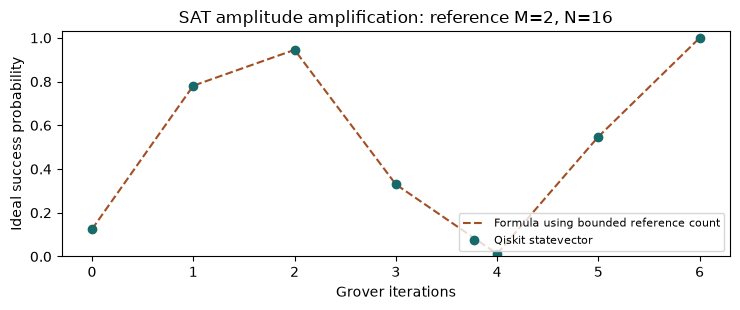

In [7]:
iterations = list(range(7))
observed = []
predicted = []
for count in iterations:
    circuit = build_sat_grover_circuit(cnf, count, measure=False)
    state = Statevector.from_instruction(circuit)
    probabilities = state.probabilities(qargs=list(range(cnf.n_variables)))
    observed.append(sum(float(probabilities[x]) for x in solutions))
    predicted.append(amplification_probability(cnf.n_variables, len(solutions), count))
np.testing.assert_allclose(observed, predicted, atol=1e-10, rtol=0)
figure, axis = plt.subplots(figsize=(7.5, 3.2))
axis.plot(iterations, predicted, "--", color="#a34f24", label="Formula using bounded reference count")
axis.plot(iterations, observed, "o", color="#176a69", label="Qiskit statevector")
axis.set(xlabel="Grover iterations", ylabel="Ideal success probability", ylim=(0, 1.03),
         title=f"SAT amplitude amplification: reference M={len(solutions)}, N={2**cnf.n_variables}")
axis.legend(fontsize=8)
figure.tight_layout()
plt.show()

## A fixed resource replay

Replay the complete recorded iteration sequence with fresh disjoint banks and final deferred measurements. This is static circuit accounting, not a timing implementation of the adaptive search: no online stopping, reset-based reuse, or serial-controller clock is represented. The generated method-page reports use the whole fixed replay and conditional synthesis/physical models.
The replay fixes iteration counts and produces fresh outcomes; it does not force the recorded measurement bitstrings.


In [8]:
recorded_iterations = [attempt["iterations"] for attempt in searches[0]["attempts"]]
replay = replay_recorded_attempts(cnf, recorded_iterations, measure=True)
print({"recorded_iterations": recorded_iterations, "fresh_bank_qubits": replay.num_qubits,
       "source_operations": dict(replay.count_ops())})

{'recorded_iterations': [0], 'fresh_bank_qubits': 9, 'source_operations': {'h': 4, 'measure': 4, 'barrier': 1}}


## Materialize a larger circuit without simulating it

The following register has 10 assignment variables, 10 clause scratch bits, and seven reusable clean work bits. It generates a decomposed circuit and OpenQASM in memory. It performs no statevector simulation, exhaustive solution count, BBHT search, or physical resource estimation.

In [9]:
larger_cnf = CNF(10, [[variable, -(variable % 10 + 1)] for variable in range(1, 11)])
preflight = preflight_sat_circuit(larger_cnf, 1)
larger = build_sat_grover_circuit(larger_cnf, iterations=1, measure=True)
decomposed = prepare_measured_circuit(larger, optimization_level=0)
qasm_text = qasm3.dumps(decomposed)
print({"assignment_qubits": larger_cnf.n_variables, "clause_scratch": len(larger_cnf.clauses), "clean_work": larger_cnf.num_clean_work_qubits,
       "total_qubits": decomposed.num_qubits, "primitive_operations": dict(decomposed.count_ops()),
       "preflight": preflight, "qasm_bytes": len(qasm_text.encode("utf-8")),
       "qasm_sha256": hashlib.sha256(qasm_text.encode("utf-8")).hexdigest()})
# To save a standalone export when desired:
# Path("sat-10.qasm").write_text(qasm_text, encoding="utf-8")

{'assignment_qubits': 10, 'clause_scratch': 10, 'clean_work': 7, 'total_qubits': 27, 'primitive_operations': {'cx': 300, 't': 200, 'tdg': 150, 'h': 134, 'x': 80, 'measure': 10}, 'preflight': {'estimated_primitive_operations': 874, 'maximum_estimated_primitive_operations': 200000, 'maximum_actual_primitive_operations': 250000, 'estimate_scope': 'Linear clean-work CCX-chain expansion preflight; actual lowering checked separately, no compiler memory/time certificate'}, 'qasm_bytes': 13882, 'qasm_sha256': 'b4a625072ee9fdc49f16883b9818f0773a868286d7495c04dc75e2e1b88742f2'}


## Interpretation

A verified candidate is a SAT witness under the supplied classical predicate. An inconclusive capped trace is not a proof of UNSAT. The separate exhaustive reference diagnoses only the tiny instances.

Physical projections of recorded fixed replays depend on the declared zero-initialization, scheduling, QEC/factory, and exact Clifford+T compiler assumptions. They do not certify unknown-count success confidence or adaptive BBHT runtime. The frozen three-qubit equality demonstration is a separate workload.